<!--
This copyright notice applies to this file only

SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
SPDX-License-Identifier: MIT

Permission is hereby granted, free of charge, to any person obtaining a
copy of this software and associated documentation files (the "Software"),
to deal in the Software without restriction, including without limitation
the rights to use, copy, modify, merge, publish, distribute, sublicense,
and/or sell copies of the Software, and to permit persons to whom the
Software is furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in
all copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL
THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING
FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER
DEALINGS IN THE SOFTWARE.
-->


# Object Detection using ThreadedDecoder

In this tutorial, we will learn one practical use case of object detection in video using PyNvVideoCodec's ThreadedDecoder class. We'll use a pre-trained Faster R-CNN model to detect objects in video frames.


## Why ThreadedDecoder?
When working on AI tasks like object detection, action recognition, or video analytics, the first step is often to decode video frames before running inference. But here’s the challenge: decoding can take time and sometimes slows down the entire pipeline.
ThreadedDecoder in PyNvVideoCodec addresses this problem. Think of it as a “background helper” that decodes frames on a separate thread while your main program focuses on inference. This means that by the time your model is ready, a batch of decoded frames is already waiting—so your pipeline runs faster and more smoothly.


<img src="ThreadedDecoder.png" alt="Normal vs Threaded Decoder" width="800"/>

Above figures illustrate the differences between a normal decoder and a threaded decoder in an inference pipeline. With the normal decoder , the inference process frequently encounters stalls while waiting for frames to be decoded since decode and inference calls are executed sequentially. In contrast, the threaded decoder overlaps decode and inference executions. The threaded decoder ensures that frames are always preloaded, allowing the inference model to process them with minimal delays.

## Package Installation

First, let's install the required packages. We'll need:
- `torch` and `torchvision`: For GPU-accelerated deep learning and object detection
- `pycuda`: For CUDA operations and GPU memory management
- `matplotlib`: For displaying frames and detection results
- `requests`: For downloading sample video
- `numpy`: For array operations

Note: 
- PyNvVideoCodec should already be installed in your environment
- For CUDA 11.8, change the install URL to `cu118`
- For CUDA 12.x, change the install URL to `cu121`
- [CUDA toolkit](https://developer.nvidia.com/cuda-toolkit) should be installed


In [ ]:
# Choose the appropriate install command based on your CUDA version:

# For CUDA 11.8:
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118

# For CUDA 12.x:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121

# Other dependencies
%pip install matplotlib requests numpy


## Setup

Let's start by importing the necessary packages for video decoding, object detection, and visualization:


In [ ]:
# Core video decoding
from PyNvVideoCodec import ThreadedDecoder, OutputColorType
import pycuda.driver as cuda
from pycuda.autoinit import context

# Deep learning and computer vision
import torch
import torchvision.models.detection as models
from torchvision.utils import draw_bounding_boxes
import torchvision.transforms.functional as F

# Data handling and utilities
import numpy as np
from pathlib import Path
import sys

# Add parent directory to path to import from sibling utils folder
parent_dir = str(Path('.').resolve().parent)
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from utils.Utils import convert_frames_to_torch

import requests
import pickle

# Visualization
import matplotlib.pyplot as plt
from IPython.display import clear_output
%matplotlib inline

## Loading Object Classes

The Faster R-CNN model we'll use is trained on the COCO dataset. Let's load the class names for interpreting the detection results:

In [11]:

# Load class names from pickle file
import pickle
coco_classes_path = "coco_classes.pickle"
with open(coco_classes_path, "rb") as f:
    CLASSES = pickle.load(f)

print(f"Loaded {len(CLASSES)} COCO classes")  # Should show 91 classes including background


Loaded 91 COCO classes


## Helper Functions for Object Detection

Let's define three utility functions to help with detection and visualization:

### 1. Filtering Detection Results

First, a function to filter detection results based on confidence threshold:

In [12]:
def get_filtered_output(input, confidence_threshold):
    """Filter detection outputs based on confidence threshold"""
    output = {}
    # Keep detections above threshold
    valid_indices = [i for i, conf in enumerate(input['scores']) if conf >= confidence_threshold]
    
    if not valid_indices:
        return None

    # Format results with class names and confidence scores
    output["boxes"] = input["boxes"][valid_indices]
    output["labels"] = filtered_labels = [input["labels"][i] for i in valid_indices]
    output["scores"] = [input["scores"][i] for i in valid_indices]
    output["labels_confidence_string"] = [f"{CLASSES[label]} {confidence:.2f}" 
                                        for label, confidence in zip(filtered_labels, output["scores"])]
    return output


### 2. Frame Visualization

Next, a function to display frames with detected objects:


In [13]:
def show_frame(img, boxes=None, labels=None):
    """Display a frame with optional bounding boxes and labels"""
    # Ensure tensor is on CPU
    img = img.cpu()
    
    # Convert to CHW format for draw_bounding_boxes
    if len(img.shape) == 3:
        if img.shape[-1] == 3:  # HWC format
            img = img.permute(2, 0, 1)  # HWC -> CHW
        elif img.shape[0] == 3:  # Already in CHW format
            pass
        else:
            raise ValueError(f"Unexpected tensor shape: {img.shape}")
    else:
        raise ValueError(f"Expected 3D tensor, got shape: {img.shape}")
    
    # Draw bounding boxes if provided
    if boxes is not None:
        img = draw_bounding_boxes(img, boxes=boxes, labels=labels, width=4)
    
    # Convert to PIL image and display
    plt.figure(figsize=(8, 4))
    plt.imshow(F.to_pil_image(img))
    plt.axis('off')
    clear_output(wait=True)
    plt.show()


### 3. Running Detection

Finally, a function to run object detection on a batch of frames:


In [14]:
def run_detection(model, frames):
    """Run object detection on a batch of frames"""
    src_tensor_list = []
    for frame in frames:
        # Convert to torch tensor and normalize to [0,1]
        src_tensor = torch.from_dlpack(frame)
        src_tensor = src_tensor.float() / 255.0
        src_tensor_list.append(src_tensor)
    
    # Run inference without gradient computation
    with torch.no_grad():
        return model(src_tensor_list)


## Loading Object Detection Model

We'll use a pre-trained Faster R-CNN model with ResNet-50 backbone:

In [15]:

# Load model and move to GPU
model = models.fasterrcnn_resnet50_fpn(pretrained=True)
model.to(torch.device('cuda'))
model.eval()  # Set to evaluation mode

c:\Users\jmukundam\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\jmukundam\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

## Preparing Input Video

For this demonstration, we'll use a sample video from [Pexels](https://www.pexels.com). First, let's create a helper function to download it:

In [16]:
# Helper function to download and save a video
def download_video(url, save_path):
    """Downloads a video from URL and saves it locally."""
    print(f"Downloading video to {save_path}...")
    response = requests.get(url, stream=True)
    with open(save_path, 'wb') as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)
    print("Download complete!")
    return save_path

Now let's download our sample video:

In [17]:
# Download a high-resolution video (2.5K at 25fps)
video_url = "https://videos.pexels.com/video-files/3196221/3196221-uhd_2560_1440_25fps.mp4"
input_video = download_video(video_url, "input.mp4")


Download complete!


## Running Object Detection

First, let's set up our ThreadedDecoder with the desired configuration.

Let's create a decoder instance with the following settings:

- `enc_file_path`: Path to our input video file
- `buffer_size` : Number of frames to prefetch and keep in the buffer
- `gpu_id`: Which GPU to use (0 for the first GPU)
- `use_device_memory`: Keep decoded frames in GPU memory for faster processing
- `output_color_type`: Choose between RGB (HWC) or RGBP (CHW) format

We'll use RGBP (planar RGB) format since it's more efficient for deep learning applications.


In [18]:
# Configure decoder parameters
color_format = OutputColorType.RGBP # Use planar RGB format (CHW). OutputColorType.RGB is also supported which is interleaved RGB format.
batch_size = 3   # Process 3 frames at a time
confidence_threshold = 0.8

# Initialize ThreadedDecoder
decoder = ThreadedDecoder(
    enc_file_path=input_video,          # Input video path
    buffer_size=12,       # Number of frames to prefetch and keep in the buffer
    gpu_id=0,            
    use_device_memory=True, # Whether to keep decoded frames in GPU memory
    output_color_type=color_format
)

# Get video information
metadata = decoder.get_stream_metadata()
num_frames = metadata.num_frames


Now let's process the video frames and run object detection:


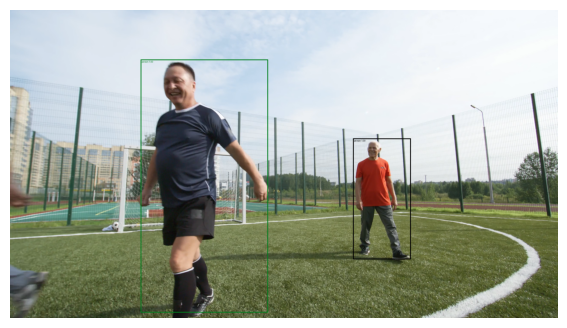

In [19]:
# Process video frames in batches
frame_count = 0
while frame_count < num_frames:
    frames = decoder.get_batch_frames(batch_size)
    if len(frames) == 0:
        break

    # Convert frames to torch tensors
    display_tensors = convert_frames_to_torch(frames, color_format)
    
    # Prepare tensors for model input (CHW format and normalize)
    model_tensors = [
        (frame.permute(2, 0, 1) if frame.shape[-1] == 3 else frame).float() / 255.0
        for frame in display_tensors
    ]
    
    # Run detection
    with torch.no_grad():
        outputs = model(model_tensors)
    
    # Display results
    for i in range(len(frames)):
        output = outputs[i]
        filtered_output = get_filtered_output(output, confidence_threshold)
        
        if filtered_output:
            show_frame(display_tensors[i], 
                    filtered_output['boxes'],
                    filtered_output['labels_confidence_string'])
        else:
            show_frame(display_tensors[i])
        
    frame_count += len(frames)


## Summary


1. The `ThreadedDecoder` efficiently decodes video frames in the background, maintaining a buffer of frames ready for processing. This parallel processing approach eliminates the typical bottleneck of sequential decode-then-inference operations.

2. As frames become available, they are immediately fed to a pre-trained Faster R-CNN model, which analyzes each frame to:
   - Detect and localize objects
   - Classify them into COCO dataset categories
   - Assign confidence scores to each detection

3. The results are visualized in real-time, with:
   - Colored bounding boxes highlighting detected objects
   - Labels showing both the object class and detection confidence
   - Smooth frame-by-frame display of the processed video

This implementation showcases how PyNvVideoCodec's threaded decoding capabilities can be seamlessly integrated with deep learning models to create efficient video analytics applications. The parallel nature of the pipeline ensures maximum GPU utilization, with the decoder preparing the next batch of frames while the model processes the current ones.
